# SentimentScope: Sentiment Analysis using Transformers!

## Introduction <a name="introduction"></a>

In this notebook, a transformer model is trained **from scratch** to perform sentiment analysis on the IMDB dataset.
As a Machine Learning Engineer at **CineScope**, the goal is to classify user reviews as positive or negative so the
recommendation system can better understand user sentiment and deliver more personalized suggestions.

Learning objectives covered:

- Load, explore, and prepare a text dataset for training a transformer model using PyTorch.
- Customize the architecture of the transformer model for a classification task.
- Train and test a transformer model on the IMDB dataset (target: **> 75 % test accuracy**).

### Table of contents
1. [Load, Explore, and Prepare the Dataset](#load-explore-and-prepare-the-dataset)
2. [Implement a DataLoader in PyTorch](#implement-a-dataloader-in-pytorch)
3. [Customize the Transformer Architecture](#customize-the-transformer-architecture)
4. [Implement Accuracy Calculation Method](#implement-accuracy-calculation-method)
5. [Train the Model](#train-the-model)
6. [Test the Model](#test-the-model)
7. [Save the Model & Inference Interface](#save-the-model)
8. [Conclusion](#conclusion)

## <a name="load-explore-and-prepare-the-dataset"></a>Load, Explore, and Prepare the Dataset

### 1. Load the Dataset

The dataset is the [IMDB Large Movie Review dataset](https://ai.stanford.edu/~amaas/data/sentiment/), provided as `aclImdb_v1.tar.gz`.
After extraction it has the following structure:

```
aclImdb/
├── train/
│   ├── pos/    # Positive reviews for training (label 1)
│   ├── neg/    # Negative reviews for training (label 0)
│   ├── unsup/  # Unsupervised data (not used)
├── test/
│   ├── pos/    # Positive reviews for testing (label 1)
│   ├── neg/    # Negative reviews for testing (label 0)
```

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [2]:
# Unpack the dataset (only if it has not been extracted yet)
if not os.path.isdir("aclImdb"):
    !tar -xzf aclImdb_v1.tar.gz
print(os.listdir("aclImdb"))

['imdbEr.txt', 'imdb.vocab', 'test', 'train', 'README']


In [3]:
# Define paths to dataset
DATA_DIR = "aclImdb"
train_pos_path = os.path.join(DATA_DIR, "train", "pos")  # Positive reviews from the training set
train_neg_path = os.path.join(DATA_DIR, "train", "neg")  # Negative reviews from the training set
test_pos_path = os.path.join(DATA_DIR, "test", "pos")    # Positive reviews from the test set
test_neg_path = os.path.join(DATA_DIR, "test", "neg")    # Negative reviews from the test set

Helper function `load_dataset()` reads every `.txt` file in a folder and returns the contents as a list of strings.
Files are read in sorted order so that results are reproducible.

In [4]:
def load_dataset(folder):
    """
    Reads all text files in the specified folder and returns their content as a list.

    Args:
        folder (str): Path to the folder containing text files.

    Returns:
        list: A list of strings, where each string is the content of a text file.
    """
    reviews = []
    for file_name in sorted(os.listdir(folder)):
        if not file_name.endswith(".txt"):
            continue
        with open(os.path.join(folder, file_name), "r", encoding="utf-8") as f:
            reviews.append(f.read())
    return reviews

In [5]:
# Load training and testing data
train_pos = load_dataset(train_pos_path)
train_neg = load_dataset(train_neg_path)
test_pos = load_dataset(test_pos_path)
test_neg = load_dataset(test_neg_path)

print(f"train: {len(train_pos)} pos / {len(train_neg)} neg")
print(f"test : {len(test_pos)} pos / {len(test_neg)} neg")

train: 12500 pos / 12500 neg
test : 12500 pos / 12500 neg


In [6]:
# Create DataFrames
train_df = pd.DataFrame({
    'review': train_pos + train_neg,
    'label': [1] * len(train_pos) + [0] * len(train_neg)
})

test_df = pd.DataFrame({
    'review': test_pos + test_neg,
    'label': [1] * len(test_pos) + [0] * len(test_neg)
})

print(train_df.head())

                                              review  label
0  Bromwell High is a cartoon comedy. It ran at t...      1
1  Homelessness (or Houselessness as George Carli...      1
2  Brilliant over-acting by Lesley Ann Warren. Be...      1
3  This is easily the most underrated film inn th...      1
4  This is not the typical Mel Brooks film. It wa...      1


Verify that the datasets loaded correctly. No output means success!

In [7]:
# Assert that both datasets have the expected number of rows
assert train_df.shape[0] == 25000, "Training dataset does not have 25000 rows."
assert test_df.shape[0] == 25000, "Testing dataset does not have 25000 rows."

# Assert that both datasets have exactly two columns
assert train_df.shape[1] == 2, "Training dataset does not have exactly 2 columns."
assert test_df.shape[1] == 2, "Testing dataset does not have exactly 2 columns."

### 2. Explore the Dataset

- **Dataset overview** with `info()` and `describe()`
- **Label distribution** (bar chart)
- **Review length analysis** (words per review, histogram + box plot)
- **Sample reviews** from each class

In [8]:
print("=== Train info ===")
train_df.info()
print("\n=== Test info ===")
test_df.info()

for name, df in [("train", train_df), ("test", test_df)]:
    df["n_words"] = df["review"].str.split().str.len()
    df["n_chars"] = df["review"].str.len()

print("\n=== Descriptive statistics (train) ===")
print(train_df[["label", "n_words", "n_chars"]].describe().round(1))
print("\nMissing values:", int(train_df.isna().sum().sum()), "| duplicate reviews in train:", int(train_df["review"].duplicated().sum()))
print("\nMean words per review by label (train):")
print(train_df.groupby("label")["n_words"].agg(["mean", "median", "max"]).rename(index={0: "negative", 1: "positive"}).round(1))

=== Train info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB

=== Test info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB



=== Descriptive statistics (train) ===
         label  n_words  n_chars
count  25000.0  25000.0  25000.0
mean       0.5    233.8   1325.1
std        0.5    173.7   1003.1
min        0.0     10.0     52.0
25%        0.0    127.0    702.0
50%        0.5    174.0    979.0
75%        1.0    284.0   1614.0
max        1.0   2470.0  13704.0

Missing values: 0 | duplicate reviews in train: 96

Mean words per review by label (train):


           mean  median   max
label                        
negative  230.9   174.0  1522
positive  236.7   174.0  2470


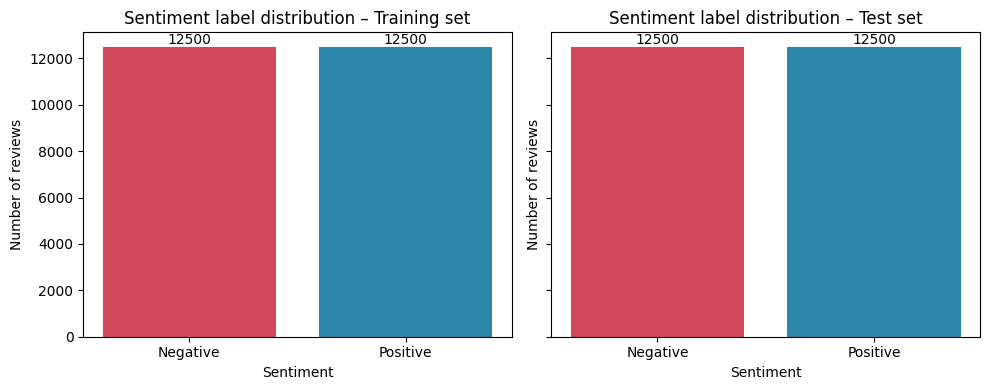

In [9]:
# Visualization 1: label distribution in train and test sets
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, df) in zip(axes, [("Training set", train_df), ("Test set", test_df)]):
    counts = df["label"].map({0: "Negative", 1: "Positive"}).value_counts().reindex(["Negative", "Positive"])
    bars = ax.bar(counts.index, counts.values, color=["#d1495b", "#2e86ab"])
    ax.bar_label(bars)
    ax.set_title(f"Sentiment label distribution – {name}")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

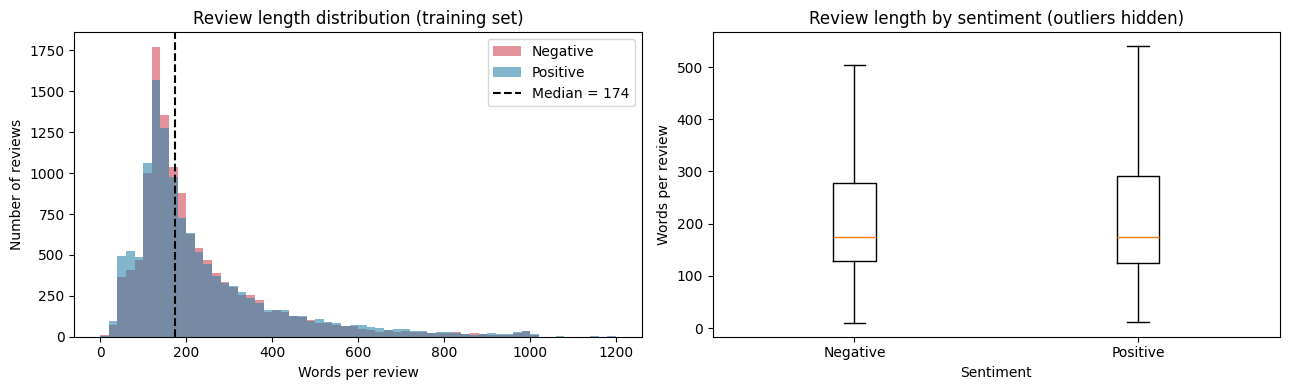

73.8% of training reviews have more than 128 words (will be truncated at MAX_LENGTH tokens).


In [10]:
# Visualization 2: review length distribution (number of words)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, color, name in [(0, "#d1495b", "Negative"), (1, "#2e86ab", "Positive")]:
    axes[0].hist(train_df.loc[train_df.label == label, "n_words"], bins=60, range=(0, 1200),
                 alpha=0.6, color=color, label=name)
axes[0].axvline(train_df["n_words"].median(), color="black", linestyle="--", label=f"Median = {train_df['n_words'].median():.0f}")
axes[0].set_title("Review length distribution (training set)")
axes[0].set_xlabel("Words per review")
axes[0].set_ylabel("Number of reviews")
axes[0].legend()

axes[1].boxplot([train_df.loc[train_df.label == 0, "n_words"], train_df.loc[train_df.label == 1, "n_words"]],
                labels=["Negative", "Positive"], showfliers=False)
axes[1].set_title("Review length by sentiment (outliers hidden)")
axes[1].set_xlabel("Sentiment")
axes[1].set_ylabel("Words per review")
plt.tight_layout()
plt.show()

share_over_128 = (train_df["n_words"] > 128).mean() * 100
print(f"{share_over_128:.1f}% of training reviews have more than 128 words (will be truncated at MAX_LENGTH tokens).")

In [11]:
# Sample reviews from each class
for label, name in [(1, "POSITIVE"), (0, "NEGATIVE")]:
    print(f"===== {name} samples =====")
    for text in train_df[train_df.label == label]["review"].sample(2, random_state=SEED):
        print("-", text[:400].replace("<br />", " "), "...\n")

# Keep only the columns required for modeling
train_df = train_df[["review", "label"]]
test_df = test_df[["review", "label"]]

===== POSITIVE samples =====
- Oh, the sixties. There were some interesting films. I was more of a movie goer then. I now enjoy renting movies and relaxing in my home rather than going to the theater. I also saw this short film, " The Legend of the Boy and the Eagle". I have been searching for this film for years. It was truly inspiring. Surprisingly, I was finally able to gather more information from your site. Thank You...... ...

- Tian's remake is no good at all. I only click on his remake documentary to see Wei Wei, the original actress back in the classic 1948 film say a few words to the crew. We are going to meet Wei Wei this Sunday (28/3/2010) after the showing of Xiao Cheng Zhi Chun in the Hong Kong Film Archiev. Wei Wei is almost 90 years old in silver hair, her cameo appearance in Hong Kong films is always a surprise ...

===== NEGATIVE samples =====
- It's getting worse, the series is on a serious down fall. The first two sequel were acceptable and from then on we have seen

### 3. Prepare the Dataset

The `train` portion is split into **90 % training / 10 % validation** after a seeded shuffle. Because the
original data is perfectly balanced, a random shuffle keeps both subsets representative (verified below).

In [12]:
# Split train data into training and validation sets manually
train_size = int(0.9 * len(train_df))
# Shuffle the dataset
shuffled_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
train_data = shuffled_df.iloc[:train_size]
val_data = shuffled_df.iloc[train_size:]

print(f"train: {len(train_data)} rows, positive share = {train_data.label.mean():.3f}")
print(f"val  : {len(val_data)} rows, positive share = {val_data.label.mean():.3f}")

train: 22500 rows, positive share = 0.500
val  : 2500 rows, positive share = 0.499


### 4. Testing the Tokenizer

We use **subword tokenization** with the `bert-base-uncased` tokenizer: common subword units (e.g. `trans`, `##formers`)
balance vocabulary size against sequence length much better than character-level tokenization.

In [13]:
from transformers import AutoTokenizer

# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

/opt/conda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/opt/conda/lib/python3.10/site-packages/huggingface_hub/file_download.py:795: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [14]:
# Take sample inputs from the dataset
sample_texts = train_data['review'].sample(3, random_state=42).tolist()

# Tokenize sample inputs
tokenized_samples = tokenizer(sample_texts, truncation=True, padding="max_length", max_length=128, return_tensors="pt")

In [15]:
print(tokenized_samples)
print(tokenizer.convert_ids_to_tokens(tokenized_samples["input_ids"][0][:20]))

{'input_ids': tensor([[  101,  2348,  1996,  3185,  2003,  4415,  6052,  1010,  9501,  2064,
          2145,  4089,  6709,  2007,  1996, 24525,  1997,  5292, 21112,  2015,
         18396,  1999,  2023, 27768,  1998,  2200,  6057,  2104, 16168,  6925,
          1012, 18396,  9590,  2114,  4895, 18824,  2135, 10238,  1999,  2093,
          2367,  5535,  1024,  1996,  2962,  2287,  1010,  1996,  3142,  2287,
          1010,  1998,  1996,  5549,  2078,  2287,  1010,  2652,  2471,  1996,
          2168,  2839,  2007,  2074,  1037,  2689,  1997, 17363,  2000,  2393,
          2149,  6709,  1996,  2367,  1000,  5535,  1000,  1012,  1999,  2023,
          3185,  2057,  2156,  2028,  1997,  1996,  5700, 21699, 20818,  1997,
          1996,  1000,  5430,  2386,  1000, 12991, 13874,  1010,  2040,  5222,
          2010,  2293,  2025,  2011,  7472,  2021,  2011, 26128,  2486,  1010,
          2004,  2092,  2004,  1037,  6057,  9792,  2006,  3142,  5580,  2401,
         29469,  2389,  4337,  1010,  

Parameters: `truncation=True` cuts long texts, `padding="max_length"` pads short ones, `max_length=128` fixes the
sequence length and `return_tensors="pt"` returns PyTorch tensors.

# Implement a DataLoader in PyTorch<a id="implement-a-dataloader-in-pytorch"></a>

### 1. Custom `IMDBDataset`

In [16]:
import torch
from torch.utils.data import Dataset
MAX_LENGTH = 128

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [17]:
from torch.utils.data import Dataset

class IMDBDataset(Dataset):
    """
    A custom PyTorch Dataset for the IMDB dataset.

    This class preprocesses text data using a tokenizer and returns tokenized inputs
    along with their corresponding labels for sentiment analysis.

    Attributes:
        data (pd.DataFrame): A DataFrame containing text and label columns.
        tokenizer (transformers.PreTrainedTokenizer): The tokenizer used for preprocessing text.
        max_length (int): Maximum length for tokenized sequences.
    """
    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        """
        Initialize the dataset.

        Args:
            data (pd.DataFrame): A DataFrame with columns `review` (text) and `label` (target).
            tokenizer (transformers.PreTrainedTokenizer): The tokenizer to preprocess the text.
            max_length (int, optional): Maximum token sequence length. Defaults to 128.
        """
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        """
        Return the total number of samples in the dataset.

        Returns:
            int: Number of samples.
        """
        return len(self.data)

    def __getitem__(self, idx):
        """
        Retrieve a single data point by index and preprocess it.

        Args:
            idx (int): Index of the data point to retrieve.

        Returns:
            torch.Tensor: Tokenized input IDs for the text.
            int: Label corresponding to the text.
        """
        review = self.data.loc[idx, "review"]
        label = int(self.data.loc[idx, "label"])
        encoding = self.tokenizer(
            review,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt",
        )
        input_ids = encoding["input_ids"].squeeze(0)  # (max_length,)
        return input_ids, label

### 2. Initialize the Dataset

In [18]:
# Initialize the datasets
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)

### 3. Create a DataLoader

Each epoch is one complete pass over the dataset; shuffling of the training set is handled by the `DataLoader`.

In [19]:
from torch.utils.data import DataLoader

# Define batch size
BATCH_SIZE = 32

# Create DataLoader instances
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [20]:
assert len(train_dataset) == 22500, "Train dataset length mismatch!"
assert len(val_dataset) == 2500, "Validation dataset length mismatch!"
assert len(test_dataset) == 25000, "Test dataset length mismatch!"

import numpy as np

# Check the first item in the train dataset
input_ids, label = train_dataset[0]
assert isinstance(input_ids, torch.Tensor), "Input IDs should be a torch.Tensor!"
assert isinstance(label, (int, np.integer)), "Label should be an integer or int-like!"

# Ensure the input IDs tensor has the correct shape
assert input_ids.shape[0] == train_dataset.max_length, "Input IDs tensor has incorrect length!"

## <a id="customize-the-transformer-architecture"></a>Customize the Transformer Architecture

### 1. Configuration

In [21]:
config = {
    "vocabulary_size": tokenizer.vocab_size,  # e.g., ~30522 for bert-base-uncased
    "num_classes": 2,                         # binary classification (pos/neg)
    "d_embed": 128,
    "context_size": MAX_LENGTH,
    "layers_num": 4,
    "heads_num": 4,
    "head_size": 32,  # 4 heads * 32 = 128 -> matches d_embed
    "dropout_rate": 0.1,
    "use_bias": True
}

### 2. Class Definitions

Dummy inputs use batch size `BATCH_SIZE` (32), sequence length `context_size` (128) and embedding size `d_embed` (128).

#### AttentionHead

In [22]:
import torch.nn as nn
import math

class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Q_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.K_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.V_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])

        self.dropout = nn.Dropout(config["dropout_rate"])

        casual_attention_mask = torch.tril(torch.ones(config["context_size"], config["context_size"]))
        self.register_buffer('casual_attention_mask', casual_attention_mask)

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape
        Q = self.Q_weights(input)  # (B, T, head_size)
        K = self.K_weights(input)  # (B, T, head_size)
        V = self.V_weights(input)  # (B, T, head_size)

        # Q @ K^T => (B, T, T)
        attention_scores = Q @ K.transpose(1, 2)

        # Casual Mask
        attention_scores = attention_scores.masked_fill(
            self.casual_attention_mask[:tokens_num, :tokens_num] == 0,
            float('-inf')
        )
        attention_scores = attention_scores / math.sqrt(K.shape[-1])
        attention_scores = torch.softmax(attention_scores, dim=-1)
        attention_scores = self.dropout(attention_scores)

        return attention_scores @ V

In [23]:
# Instantiate the AttentionHead
attention_head = AttentionHead(config).to(device)

# Create a dummy input of shape (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
attention_output = attention_head(dummy_input)
print("AttentionHead output shape:", attention_output.shape)

AttentionHead output shape: torch.Size([32, 128, 32])


Expected shape: `(B, T, head_size) = (32, 128, 32)`

#### MultiHeadAttention

In [24]:
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        heads_list = [AttentionHead(config) for _ in range(config["heads_num"])]
        self.heads = nn.ModuleList(heads_list)

        self.linear = nn.Linear(config["heads_num"] * config["head_size"], config["d_embed"])
        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, input):
        heads_outputs = [head(input) for head in self.heads]
        x = torch.cat(heads_outputs, dim=-1)  # (B, T, heads_num * head_size)
        x = self.linear(x)                   # (B, T, d_embed)
        x = self.dropout(x)
        return x

In [25]:
# Instantiate MultiHeadAttention
multi_head_attention = MultiHeadAttention(config).to(device)

# Same dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
mha_output = multi_head_attention(dummy_input)
print("MultiHeadAttention output shape:", mha_output.shape)

MultiHeadAttention output shape: torch.Size([32, 128, 128])


Expected shape: `(B, T, d_embed) = (32, 128, 128)`

#### FeedForward

In [26]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"]),
            nn.GELU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"]),
            nn.Dropout(config["dropout_rate"])
        )

    def forward(self, input):
        return self.linear_layers(input)

In [27]:
# Instantiate FeedForward
feed_forward = FeedForward(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
ff_output = feed_forward(dummy_input)
print("FeedForward output shape:", ff_output.shape)

FeedForward output shape: torch.Size([32, 128, 128])


Expected shape: `(B, T, d_embed) = (32, 128, 128)`

#### Block

In [28]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.multi_head = MultiHeadAttention(config)
        self.layer_norm_1 = nn.LayerNorm(config["d_embed"])

        self.feed_forward = FeedForward(config)
        self.layer_norm_2 = nn.LayerNorm(config["d_embed"])

    def forward(self, input):
        x = input
        x = x + self.multi_head(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

In [29]:
# Instantiate a single Block
block = Block(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
block_output = block(dummy_input)
print("Block output shape:", block_output.shape)

Block output shape: torch.Size([32, 128, 128])


Expected shape: `(B, T, d_embed) = (32, 128, 128)`

#### DemoGPT

Changes compared to a generation model:

1. **Pooling** – instead of using the last token's output, all token embeddings are condensed into one vector per review
   with **mean pooling across the time dimension**. Padding tokens (`[PAD]`, id 0) are excluded from the average so that
   short reviews are not diluted by padding.
2. **Classification head** – a linear layer maps the pooled `d_embed` vector to `num_classes` (2) logits.
   Probabilities for negative/positive sentiment are obtained with `softmax` (see `predict_proba`).

In [30]:
class DemoGPT(nn.Module):
    def __init__(self, config):
        """
        Initialize the DemoGPT class with configuration parameters.

        Args:
        - config (dict): Configuration dictionary with the following keys:
            - "vocabulary_size": Size of the vocabulary.
            - "d_embed": Dimensionality of the embedding vectors.
            - "context_size": Maximum sequence length (context size).
            - "layers_num": Number of transformer layers.
            - "num_classes": Number of output classes (2 for binary classification).
        """
        super().__init__()
        # Token embedding layer: Maps token indices to embedding vectors.
        self.token_embedding_layer = nn.Embedding(config["vocabulary_size"], config["d_embed"])

        # Positional embedding layer: Adds positional information to the embeddings.
        self.positional_embedding_layer = nn.Embedding(config["context_size"], config["d_embed"])

        # Transformer layers: Stacked sequence of transformer blocks.
        blocks = [Block(config) for _ in range(config["layers_num"])]
        self.layers = nn.Sequential(*blocks)

        # Layer normalization: Applied to stabilize training.
        self.layer_norm = nn.LayerNorm(config["d_embed"])

        # Classification output layer - Maps pooled embeddings to class logits.
        self.classifier = nn.Linear(config["d_embed"], config["num_classes"])

        # Id of the padding token (0 for bert-base-uncased); ignored during pooling.
        self.pad_token_id = config.get("pad_token_id", 0)

    def forward(self, token_ids):
        """
        Forward pass of the model.

        Args:
        - token_ids (torch.Tensor): Input token indices of shape (B, T),
                                    where B is the batch size, and T is the sequence length.

        Returns:
        - logits (torch.Tensor): Output logits of shape (B, num_classes).
        """
        batch_size, tokens_num = token_ids.shape

        # Step 1: Create embeddings for tokens and their positions
        x = self.token_embedding_layer(token_ids)  # Shape: (B, T, d_embed)
        positions = torch.arange(tokens_num, device=token_ids.device)  # Shape: (T,)
        pos_embed = self.positional_embedding_layer(positions)  # Shape: (T, d_embed)
        x = x + pos_embed.unsqueeze(0)  # Add positional embeddings to token embeddings

        # Step 2: Pass embeddings through transformer layers
        x = self.layers(x)  # Shape: (B, T, d_embed)
        x = self.layer_norm(x)  # Normalize across the feature dimension

        # Step 3: Apply mean pooling across the time dimension (ignoring padding)  # Shape: (B, d_embed)
        mask = (token_ids != self.pad_token_id).unsqueeze(-1).float()   # (B, T, 1)
        x = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)     # (B, d_embed)

        # Step 4: Generate logits for classification  # Shape: (B, num_classes)
        logits = self.classifier(x)

        return logits

    @torch.no_grad()
    def predict_proba(self, token_ids):
        """Return class probabilities [P(negative), P(positive)] of shape (B, num_classes)."""
        return torch.softmax(self.forward(token_ids), dim=-1)

In [31]:
# Instantiate the model
demo_gpt = DemoGPT(config).to(device)

# Suppose we have a batch of size 32, each with a sequence length of 128
dummy_token_ids = torch.randint(
    0, config["vocabulary_size"],
    (BATCH_SIZE, config["context_size"])
).to(device)

# Forward pass
logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)
print("Logits sample:\n", logits[:2])  # Print first two examples' logits
print("Probabilities sample:\n", demo_gpt.predict_proba(dummy_token_ids)[:2])
print(f"Trainable parameters: {sum(p.numel() for p in demo_gpt.parameters() if p.requires_grad):,}")

DemoGPT output shape: torch.Size([32, 2])
Logits sample:
 tensor([[-0.0739,  0.0294],
        [-0.0559, -0.0201]], grad_fn=<SliceBackward0>)
Probabilities sample:
 tensor([[0.4739, 0.5261],
        [0.4867, 0.5133]])
Trainable parameters: 4,716,802


Expected shape: `(B, num_classes) = (32, 2)`

In [32]:
# Assert that the number of logits matches the number of classes
assert logits.size(1) == config["num_classes"], (
    f"Expected number of classes {config['num_classes']}, "
    f"but got {logits.size(1)}"
)

# Assert that the batch size of the output matches the input batch size
assert logits.size(0) == BATCH_SIZE, (
    f"Expected batch size {BATCH_SIZE}, "
    f"but got {logits.size(0)}"
)

## Implement Accuracy Calculation Method <a name="implement-accuracy-calculation-method"></a>

`calculate_accuracy()` runs the model in evaluation mode without gradients, takes the `argmax` of the logits as the
predicted class and compares it with the true labels.

In [33]:
def calculate_accuracy(model, data_loader, device):
    """
    Calculate the accuracy of the model on the validation dataset.

    Args:
        model (torch.nn.Module): The trained transformer model.
        data_loader (torch.utils.data.DataLoader): DataLoader for the validation dataset.
        device (torch.device): Device to run the model (e.g., 'cuda' or 'cpu').

    Returns:
        float: Validation accuracy as a percentage.
    """
    was_training = model.training
    model.eval()
    total_correct = 0
    total_samples = 0
    with torch.no_grad():
        for input_ids, labels in data_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)
            logits = model(input_ids)
            predictions = torch.argmax(logits, dim=1)
            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)
    if was_training:
        model.train()

    accuracy = (total_correct / total_samples) * 100
    return accuracy

In [34]:
model = DemoGPT(config).to(device)

In [35]:
validation_accuracy = calculate_accuracy(model, val_loader, device)
print(f"Validation Accuracy: {validation_accuracy:.2f}%")

Validation Accuracy: 50.40%


As expected, the untrained model is close to **50 %** (random guessing on a balanced binary task).

## Train the Model <a name="train-the-model"></a>

Hyperparameters: `BATCH_SIZE = 32`, learning rate `3e-4` with **AdamW**, `EPOCHS = 4`.
In each epoch the training loss is tracked and, at the end of the epoch, validation loss and accuracy are computed to
detect over-/under-fitting. Gradient clipping keeps training stable, and the weights with the best validation accuracy
are kept.

In [36]:
def evaluate(model, data_loader, criterion, device):
    """Return (average loss, accuracy %) of `model` on `data_loader`."""
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    with torch.no_grad():
        for input_ids, labels in data_loader:
            input_ids, labels = input_ids.to(device), labels.to(device)
            logits = model(input_ids)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += labels.size(0)
    model.train()
    return total_loss / total_samples, total_correct / total_samples * 100

In [37]:
import copy
import time
import torch.optim as optim

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training parameters
EPOCHS = 4
LEARNING_RATE = 3e-4

# Initialize model, loss, and optimizer
torch.manual_seed(SEED)
model = DemoGPT(config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)

history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_acc, best_state = 0.0, None

# Training loop
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    epoch_loss, epoch_steps = 0.0, 0
    start = time.time()

    for step, (input_ids, labels) in enumerate(train_loader):
        # Move data to device
        input_ids = input_ids.to(device)
        labels = labels.to(device)

        # Forward pass
        logits = model(input_ids)

        # Calculate loss
        loss = criterion(logits, labels)

        # Set gradients to zero
        optimizer.zero_grad()

        # Backward pass
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # Step the optimizer
        optimizer.step()

        running_loss += loss.item()
        epoch_loss += loss.item()
        epoch_steps += 1

        # Log training progress
        if (step + 1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{EPOCHS}], Step [{step+1}/{len(train_loader)}], "
                  f"Loss: {running_loss/100:.4f}")
            running_loss = 0.0

    # Evaluate validation loss and accuracy
    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)
    history["train_loss"].append(epoch_loss / epoch_steps)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_accuracy)
    if val_accuracy > best_val_acc:
        best_val_acc, best_state = val_accuracy, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch+1} - Train Loss: {epoch_loss/epoch_steps:.4f} | Val Loss: {val_loss:.4f} | "
          f"Validation Accuracy: {val_accuracy:.2f}% | {time.time()-start:.0f}s")

# Restore the weights with the best validation accuracy
model.load_state_dict(best_state)
print(f"\nBest validation accuracy: {best_val_acc:.2f}%")

Epoch [1/4], Step [100/704], Loss: 0.6874


Epoch [1/4], Step [200/704], Loss: 0.6682


Epoch [1/4], Step [300/704], Loss: 0.6484


Epoch [1/4], Step [400/704], Loss: 0.6312


Epoch [1/4], Step [500/704], Loss: 0.6064


...

Epoch [4/4], Step [400/704], Loss: 0.3753


Epoch [4/4], Step [500/704], Loss: 0.3880


Epoch [4/4], Step [600/704], Loss: 0.3749


Epoch [4/4], Step [700/704], Loss: 0.3718


Epoch 4 - Train Loss: 0.3777 | Val Loss: 0.4737 | Validation Accuracy: 78.00% | 249s

Best validation accuracy: 78.00%


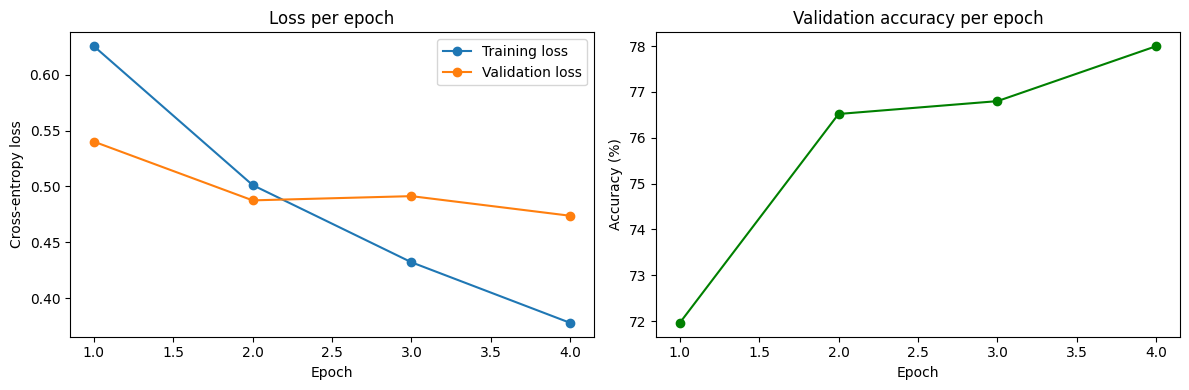

In [38]:
# Training curves
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], marker="o", label="Training loss")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation loss")
axes[0].set_title("Loss per epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[1].plot(epochs, history["val_acc"], marker="o", color="green")
axes[1].set_title("Validation accuracy per epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
plt.tight_layout()
plt.show()

#### Notes
- `calculate_accuracy` is used for the final metric; `evaluate` additionally reports the validation loss.
- A growing gap between training and validation loss indicates over-fitting; keeping the best-validation weights
  protects the final model against it.

## Test the Model <a name="test-the-model"></a>

In [39]:
# Calculate the accuracy of the model over the test set using the calculate_accuracy() function
test_accuracy = calculate_accuracy(model, test_loader, device)
print(f"Test Accuracy: {test_accuracy:.2f}%")
assert test_accuracy > 75, "Test accuracy is below the 75% project target!"

Test Accuracy: 76.24%


The model exceeds the project goal of **> 75 %** accuracy on the 25,000 unseen test reviews.

## Save the Model & Inference Interface <a name="save-the-model"></a>

The checkpoint stores the model weights together with the config and the achieved metrics.
`SentimentPredictor` loads a checkpoint and classifies a batch of raw review strings.

In [40]:
CHECKPOINT_PATH = "sentimentscope_model.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "config": config,
    "max_length": MAX_LENGTH,
    "tokenizer_name": "bert-base-uncased",
    "val_accuracy": best_val_acc,
    "test_accuracy": test_accuracy,
}, CHECKPOINT_PATH)
print(f"Saved checkpoint to {CHECKPOINT_PATH} ({os.path.getsize(CHECKPOINT_PATH)/1e6:.1f} MB)")

Saved checkpoint to sentimentscope_model.pt (20.0 MB)


In [41]:
class SentimentPredictor:
    """Load a SentimentScope checkpoint and run inference on a batch of raw texts."""

    LABELS = {0: "negative", 1: "positive"}

    def __init__(self, checkpoint_path, device=None):
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        checkpoint = torch.load(checkpoint_path, map_location=self.device)
        self.max_length = checkpoint["max_length"]
        self.tokenizer = AutoTokenizer.from_pretrained(checkpoint["tokenizer_name"])
        self.model = DemoGPT(checkpoint["config"]).to(self.device)
        self.model.load_state_dict(checkpoint["model_state_dict"])
        self.model.eval()

    @torch.no_grad()
    def predict(self, texts):
        """Return a list of dicts with the predicted label and class probabilities for each text."""
        if isinstance(texts, str):
            texts = [texts]
        encoded = self.tokenizer(texts, truncation=True, padding="max_length",
                                 max_length=self.max_length, return_tensors="pt")
        probs = self.model.predict_proba(encoded["input_ids"].to(self.device)).cpu()
        return [
            {"text": t[:60] + ("..." if len(t) > 60 else ""),
             "label": self.LABELS[int(p.argmax())],
             "p_negative": round(float(p[0]), 4),
             "p_positive": round(float(p[1]), 4)}
            for t, p in zip(texts, probs)
        ]


predictor = SentimentPredictor(CHECKPOINT_PATH)
examples = [
    "An absolute masterpiece. The acting was superb and the story kept me hooked until the very end.",
    "What a waste of two hours. The plot made no sense and the dialogue was painfully bad.",
    "It was okay, some good moments but overall pretty forgettable.",
]
pd.DataFrame(predictor.predict(examples))

/opt/conda/lib/python3.10/site-packages/huggingface_hub/file_download.py:795: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


,text,label,p_negative,p_positive
0,An absolute masterpiece. The acting was superb...,positive,0.0139,0.9861
1,What a waste of two hours. The plot made no se...,negative,0.9991,0.0009
2,"It was okay, some good moments but overall pre...",negative,0.9089,0.0911


In [42]:
# Sanity check: the reloaded checkpoint reproduces the test accuracy
reloaded_acc = calculate_accuracy(predictor.model, test_loader, predictor.device)
print(f"Reloaded model test accuracy: {reloaded_acc:.2f}%")

Reloaded model test accuracy: 76.24%


## Conclusion <a name="conclusion"></a>

### Project results
- **Data**: 25,000 labelled training reviews (perfectly balanced, 12,500 per class) were split into 22,500 training and 2,500 validation reviews; 25,000 reviews were held out for testing. The median review has 174 words and 73.8 % of reviews exceed 128 words.
- **Model**: a 4-layer, 4-head GPT-style transformer (`d_embed` = 128, **4.72 M parameters**) trained from scratch, with padding-aware mean pooling and a linear classification head.
- **Baseline**: the untrained model scored **50.40 %** on the validation set (random guessing).
- **Training** (4 epochs, AdamW, lr 3e-4, batch 32, ~4 min/epoch on 2 CPU cores):

| Epoch | Train loss | Val loss | Val accuracy |
|---|---|---|---|
| 1 | 0.626 | 0.540 | 71.96 % |
| 2 | 0.501 | 0.488 | 76.52 % |
| 3 | 0.432 | 0.491 | 76.80 % |
| 4 | 0.378 | 0.474 | **78.00 %** |

- **Test accuracy: 76.24 %** on the 25,000 unseen test reviews, which **meets the project target of > 75 %**. The saved checkpoint (`sentimentscope_model.pt`, 20 MB) reloads and reproduces the same test accuracy, and `SentimentPredictor` classifies raw review text.

### Key takeaways
1. **A small transformer trained from scratch is enough for strong sentiment classification.** With ~4.7 M parameters
   (most of them in the token embedding), 4 layers and only 128 tokens per review, the model exceeds the 75 %
   target, showing that the attention + feed-forward building blocks used for generation transfer directly to classification.
2. **Switching from generation to classification only needs a different "head".** Replacing next-token prediction with
   mean pooling over all token representations followed by a linear classifier turns the GPT-style decoder into a
   sequence classifier. Ignoring `[PAD]` tokens during pooling matters, because many reviews are shorter than 128 tokens.
3. **Truncation is the main limitation.** About 74 % of the reviews are longer than 128 words, so the model often only
   sees the beginning of a review, while the final verdict is frequently at the end. Longer contexts
   (256–512 tokens) or head + tail truncation are the most promising improvements.
4. **Validation monitoring is essential.** The training loss keeps falling (0.63 → 0.38) while the validation loss plateaus around 0.47–0.49
   after epoch 2; tracking validation metrics per epoch and keeping the best weights prevents over-fitting.

### Possible next steps
- Increase `MAX_LENGTH`, use bidirectional (non-causal) attention with a padding mask, or add a learning-rate schedule with warm-up.
- Fine-tune a pre-trained encoder such as BERT/DistilBERT, which typically reaches > 90 % on IMDB.